# Challenge 1

1. Go to this link https://learn.arcgis.com/en/projects/map-and-analyze-the-urban-heat-island-effect/ and follow all the instructions provided. The ETA for this tutorial is 40 mins, but I guess it will take you around 1 hour if you are not familiar with ArcGIS Online.

2. After completing the tutorial, please take a screenshot of your final dashboard and include it in the next markdown cell along with the dashboard link. This is a key step as I will validate the image againts the link you will provide, make sure you share the dasboard with the corresponding group in ArcGIS Online. That is, in the step 11 of the **Finish the map** section instead of sharing to **everyone**, you need to clic in **Edit group sharing** and then find the corresponding group where I will be able to see the dashboard. 

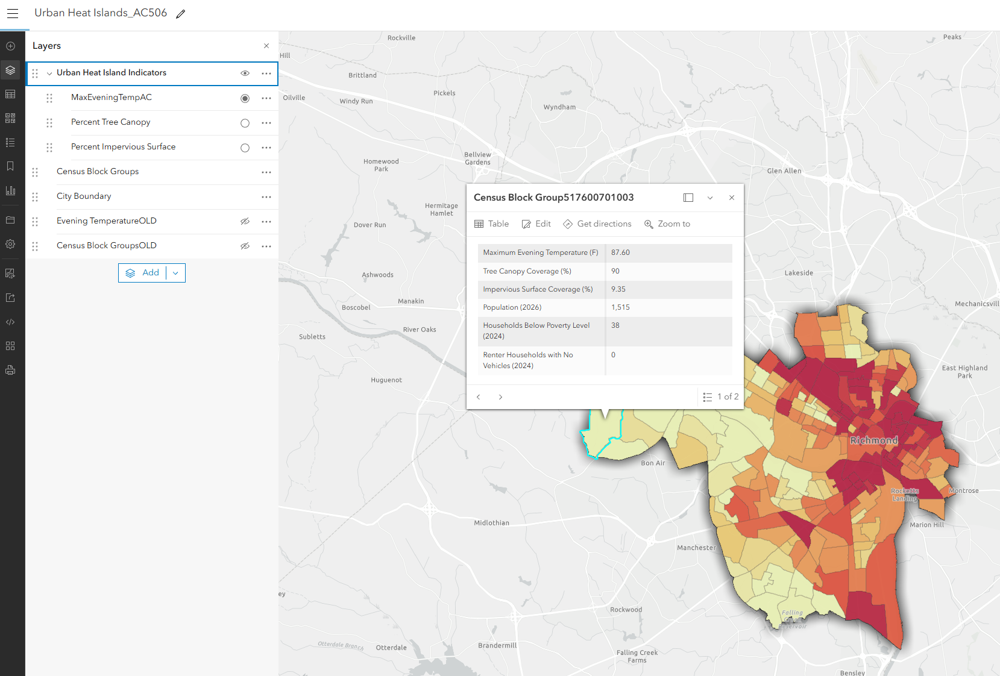

https://arcg.is/1HbmiC5

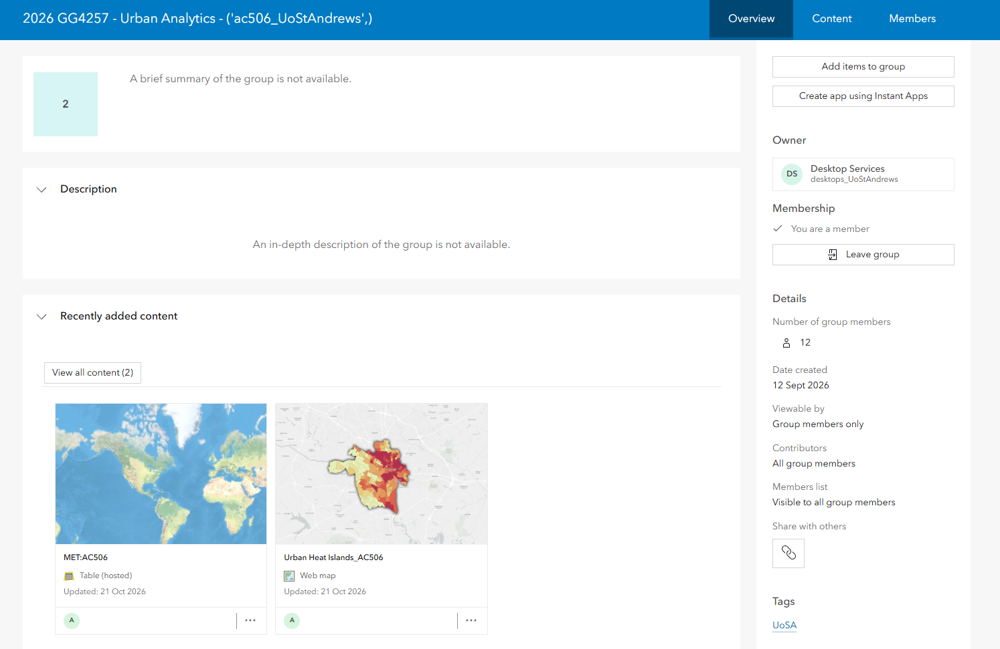

# Challenge 2
 
Now is the time for you to create some choropleth maps. 

1. Go to this portal https://www.spatialdata.gov.scot/geonetwork/srv/eng/catalog.search#/home
2. Get the Scottish Index of Multiple Deprivation (SIMD) 2020 dataset and extract the data only for the city of Edinburgh.
3. Create two static choropleth maps (e.g. `matplotlib`). These maps should represent an attribute you find interesting in the SIMD dataset. Using two different classifier methods, you need to show how the maps appear different even though the data and attributes are the same. Include a clear description of your choice and the difference in the classification method for the attribute chosen (e.g. Plotting histograms with breakpoints(bins)). You can find a complete list of classifiers at https://pysal.org/mapclassify/api.html.
4. Finally, create other two interactive maps (e.g. `choropleth_map`) - one for Glasgow and one for Edinburgh - to represent the difference in deprivation for both cities. Pick any of the available attributes., what is relevant is you can visualise how different both scottish cities are.

   > As always include the appropriate descriptions and code comments where you describe how you are processing the data and the insights you get from the results. Avoid to use AI for this, as the challenges are part of submitted work, and it is really easy to detect if you are using AI to generate the code or the comments, you will be reported for academic misconduct. 

In [3]:
#Making the plot with Plotly

import plotly.express as px
import geopandas as gpd

#Read the shapefile and convert into GeoDataFrame with GeoPandas

shapefile_path = r'SG_SIMD_2020\SG_SIMD_2020.shp'
gdf = gpd.read_file(shapefile_path)

In [10]:
gdf.head

#Exploring the data, ensuring what we need is here 

<bound method NDFrame.head of        DataZone               DZName         LAName  SAPE2017  WAPE2017  \
0     S01006506          Culter - 01  Aberdeen City       894       580   
1     S01006507          Culter - 02  Aberdeen City       793       470   
2     S01006508          Culter - 03  Aberdeen City       624       461   
3     S01006509          Culter - 04  Aberdeen City       537       307   
4     S01006510          Culter - 05  Aberdeen City       663       415   
...         ...                  ...            ...       ...       ...   
6971  S01013477  Broxburn South - 06   West Lothian       612       355   
6972  S01013478   Broxburn East - 01   West Lothian       817       582   
6973  S01013479   Broxburn East - 02   West Lothian       785       479   
6974  S01013480   Broxburn East - 03   West Lothian       677       410   
6975  S01013481   Broxburn East - 04   West Lothian       462       305   

      Rankv2  Quintilev2  Decilev2  Vigintilv2  Percentv2  ... CrimeR

In [5]:
gdf.columns

#Which column can I use to extract only Edinburgh's SimD data from

Index(['DataZone', 'DZName', 'LAName', 'SAPE2017', 'WAPE2017', 'Rankv2',
       'Quintilev2', 'Decilev2', 'Vigintilv2', 'Percentv2', 'IncRate',
       'IncNumDep', 'IncRankv2', 'EmpRate', 'EmpNumDep', 'EmpRank', 'HlthCIF',
       'HlthAlcSR', 'HlthDrugSR', 'HlthSMR', 'HlthDprsPc', 'HlthLBWTPc',
       'HlthEmergS', 'HlthRank', 'EduAttend', 'EduAttain', 'EduNoQuals',
       'EduPartici', 'EduUniver', 'EduRank', 'GAccPetrol', 'GAccDTGP',
       'GAccDTPost', 'GAccDTPsch', 'GAccDTSsch', 'GAccDTRet', 'GAccPTGP',
       'GAccPTPost', 'GAccPTRet', 'GAccBrdbnd', 'GAccRank', 'CrimeCount',
       'CrimeRate', 'CrimeRank', 'HouseNumOC', 'HouseNumNC', 'HouseOCrat',
       'HouseNCrat', 'HouseRank', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='object')

In [6]:
gdf["LAName"].unique()

#Utalise Unqique. function on column LAName to identify Edinburgh City

array(['Aberdeen City', 'Aberdeenshire', 'Angus', 'Argyll and Bute',
       'Clackmannanshire', 'Dumfries and Galloway', 'Dundee City',
       'East Ayrshire', 'East Dunbartonshire', 'East Lothian',
       'East Renfrewshire', 'City of Edinburgh', 'Na h-Eileanan an Iar',
       'Falkirk', 'Fife', 'Glasgow City', 'Highland', 'Inverclyde',
       'Midlothian', 'Moray', 'North Ayrshire', 'North Lanarkshire',
       'Orkney Islands', 'Perth and Kinross', 'Renfrewshire',
       'Scottish Borders', 'Shetland Islands', 'South Ayrshire',
       'South Lanarkshire', 'Stirling', 'West Dunbartonshire',
       'West Lothian'], dtype=object)

In [8]:
Edinburgh_Wards = gdf[gdf["LAName"] == "City of Edinburgh"]
Edinburgh_Wards.head

#Extract rows with City of Edinburgh defined
#Display head to identify whether it worked

<bound method NDFrame.head of        DataZone                               DZName             LAName  \
1911  S01008417  Balerno and Bonnington Village - 01  City of Edinburgh   
1912  S01008418  Balerno and Bonnington Village - 02  City of Edinburgh   
1913  S01008419  Balerno and Bonnington Village - 03  City of Edinburgh   
1914  S01008420  Balerno and Bonnington Village - 04  City of Edinburgh   
1915  S01008421  Balerno and Bonnington Village - 05  City of Edinburgh   
...         ...                                  ...                ...   
2503  S01009009                Queensferry West - 01  City of Edinburgh   
2504  S01009010                Queensferry West - 02  City of Edinburgh   
2505  S01009011                Queensferry West - 03  City of Edinburgh   
2506  S01009012                Queensferry West - 04  City of Edinburgh   
2507  S01009013                Queensferry West - 05  City of Edinburgh   

      SAPE2017  WAPE2017  Rankv2  Quintilev2  Decilev2  Vigintilv2  P

In [11]:
Edinburgh_Wards.explore()
#Followed by a further visual check, success. 

In [12]:
Edinburgh_Wards.set_index('DataZone', inplace=True)
Edinburgh_Wards.head()

#Set index of GeoDataFrame to DataZone column as seen in example, giving a unique identifier, enabling easier analysis and referencing.

,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,IncRate,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
DataZone,,,,,,,,,,,,,,,,,,,,,
S01008417,Balerno and Bonnington Village - 01,City of Edinburgh,708,397,5537,4,8,16,80,5%,...,86,5392.0,17,8,2%,1%,6350.0,20191.721420,1.029993e+07,"POLYGON ((315157.369 666212.846, 315173.727 66..."
S01008418,Balerno and Bonnington Village - 02,City of Edinburgh,691,378,6119,5,9,18,88,2%,...,103,5063.0,7,10,1%,1%,6650.0,25944.861787,2.357050e+07,"POLYGON ((317816.000 666579.000, 318243.000 66..."
S01008419,Balerno and Bonnington Village - 03,City of Edinburgh,541,338,5200,4,8,15,75,5%,...,187,3594.0,30,0,6%,0%,5372.5,5738.935106,1.366457e+06,"POLYGON ((316831.000 667049.000, 316816.000 66..."
S01008420,Balerno and Bonnington Village - 04,City of Edinburgh,466,274,6431,5,10,19,93,2%,...,109,4957.0,2,0,0%,0%,6957.0,1890.096713,1.051967e+05,"POLYGON ((316368.000 666124.000, 316379.297 66..."
S01008421,Balerno and Bonnington Village - 05,City of Edinburgh,884,537,3441,3,5,10,50,10%,...,264,2575.0,61,6,7%,1%,4598.0,2645.609037,1.465441e+05,"POLYGON ((316411.427 666596.771, 316422.940 66..."


In [13]:
import plotly.io as pio
pio.renderers.default = "notebook_connected"

#Import plotly as pio

In [14]:
Edinburgh_Wards = Edinburgh_Wards.to_crs(epsg=4326)

#Converted Crs to epsg4326 to ensure geometries are positioned within the visible map, giving plausable long/lat within UK

In [87]:
fig = px.choropleth_map(
    Edinburgh_Wards,
    geojson=Edinburgh_Wards.geometry,
    locations=Edinburgh_Wards.index,
    color="IncRankv2",
    color_continuous_scale="Viridis",
    hover_name="DZName",
    labels={"DZName": "IncRankv2"},
    map_style="carto-positron",
    center={"lat": 55.95, "lon": -3.19},
    zoom=9.5,
    opacity=0.8,
)
fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0})
fig.show()

#Replicated Plotly chloropleth map creation code from example

#Based the chloropleth on Income Domain Rank in Edinburgh with labels displaying Data Zone Name, Number and Income Domaine Rank.

#adjusted lat and lon to be Edinburgh area so it immediately opens up on which. 

#Adjusted zoom for similar reason of polishing. 

In [33]:
import mapclassify as mc
import matplotlib.pyplot as plt
import folium
import seaborn as sns

#Imported mapclassify from PySal in order to choose an appropriate classification method, as Chloropleth maps are subjective. 

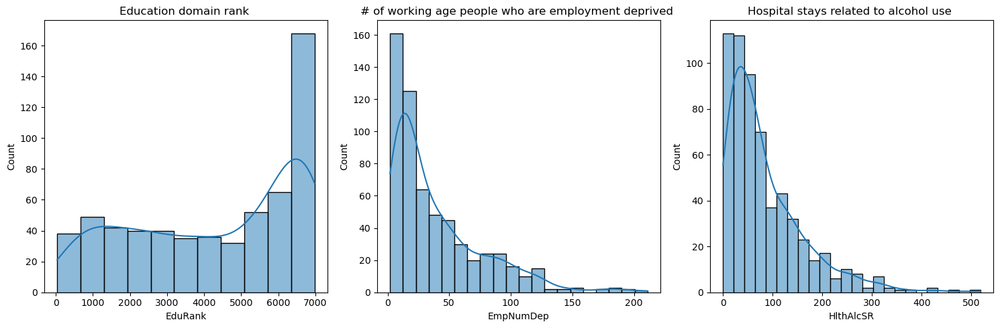

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(data=Edinburgh_Wards, x="EduRank",ax=axes[0], kde=True) 
sns.histplot(data=Edinburgh_Wards, x="EmpNumDep",ax=axes[1], kde=True)
sns.histplot(data=Edinburgh_Wards, x="HlthAlcSR",ax=axes[2], kde=True) 

axes[0].set_title("Education domain rank ")
axes[1].set_title("# of working age people who are employment deprived ")
axes[2].set_title("Hospital stays related to alcohol use ")

plt.tight_layout()
plt.show()

#Plotted histograms based on:   #Education Ranking 
                                #Working age population who are employment deprived
                                #Hospital stays related to alcohol use

#Replicated code from given example, plotting 3 histograms with appropriate corresponding titles.

#Tight layout for clean visual then displaying it. 

In [35]:
# Number of classes for classification
num_classes = 5

# Using Natural Breaks  classification
classifier_nb = mc.NaturalBreaks(Edinburgh_Wards['EduRank'], k=num_classes)
print(classifier_nb)
print(min(classifier_nb.bins), max(classifier_nb.bins))
print(classifier_nb.bins) 

# Using Equal Interval classification
classifier_ei = mc.EqualInterval(Edinburgh_Wards['EduRank'], k=num_classes)
print(classifier_ei)
print(min(classifier_ei.bins), max(classifier_ei.bins))
print(classifier_ei.bins)

#Replicated code from given example, utalising Natural Break classification to minimise within class variance while maximising between class variance. 
#This method handles this type of data better as data can often not be spread out evenly.

#nb = Natural Breaks classification.
#ei = Equal Interval classification.

#Proceeding with Education Ranking as the variable

NaturalBreaks

     Interval        Count
--------------------------
[  35.00, 1625.00] |   114
(1625.00, 3154.00] |    95
(3154.00, 4666.00] |    85
(4666.00, 6057.00] |   105
(6057.00, 6976.00] |   198
1625.0 6976.0
[1625. 3154. 4666. 6057. 6976.]
EqualInterval

     Interval        Count
--------------------------
[  35.00, 1423.20] |    94
(1423.20, 2811.40] |    93
(2811.40, 4199.60] |    79
(4199.60, 5587.80] |    82
(5587.80, 6976.00] |   249
1423.2 6976.0
[1423.2 2811.4 4199.6 5587.8 6976. ]


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


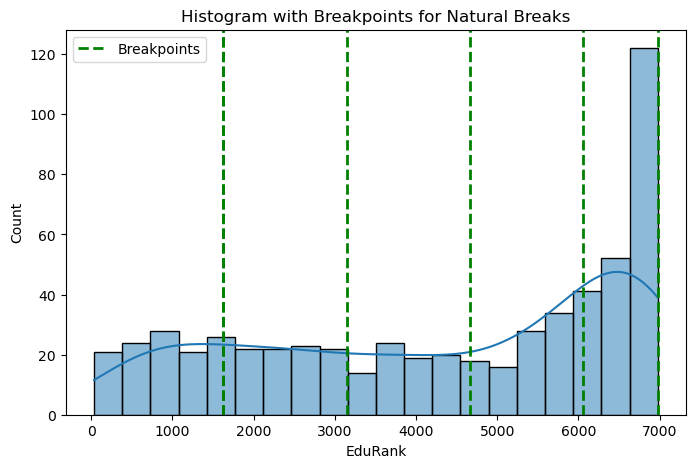

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(data=Edinburgh_Wards, x="EduRank", ax=ax, kde=True, bins=20)

#Plot breakpoints along histogram to identify how data is being classified 

ax.axvline(classifier_nb.bins[0], color='green', linestyle='dashed', linewidth=2, label='Breakpoints') 

#Defined break points with visual attributes, e.g. colour, linestyle, etc. 

for bin_value in classifier_nb.bins:
    ax.axvline(bin_value, color='green', linestyle='dashed', linewidth=2)

#This loops the breakpoint as to have multiple breakpoints and not just the first one. 

ax.set_title("Histogram with Breakpoints for Natural Breaks")

#Give appropriate title 

plt.legend()
plt.show()

#Legend and display

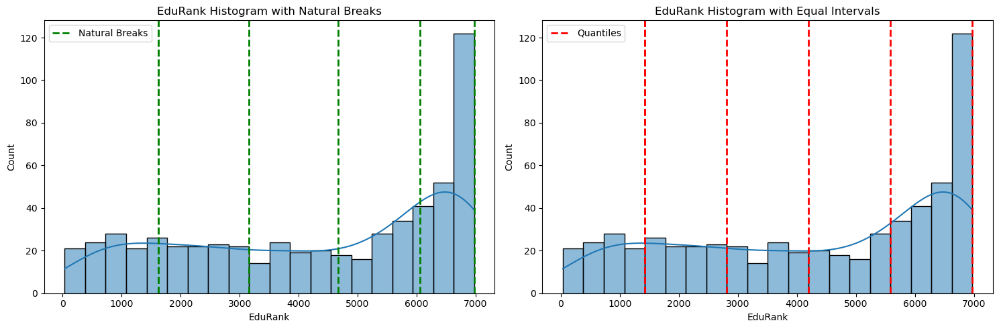

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=Edinburgh_Wards, x='EduRank', ax=axes[0], kde=True, bins=20)
axes[0].axvline(classifier_nb.bins[0], color='green', linestyle='dashed', linewidth=2, label='Natural Breaks')
for bin_value in classifier_nb.bins:
    axes[0].axvline(bin_value, color='green', linestyle='dashed', linewidth=2)
axes[0].set_title("EduRank Histogram with Natural Breaks")
axes[0].legend()

#Similar replicated process as before however with one extra property.

#Axis [0] and Axis [1] ensures tables are differentiated in code and show both while not overlapping or causing errors. 

sns.histplot(data=Edinburgh_Wards, x="EduRank", ax=axes[1], kde=True, bins=20)
axes[1].axvline(classifier_ei.bins[0], color='red', linestyle='dashed', linewidth=2, label='Quantiles')
for bin_value in classifier_ei.bins:
    axes[1].axvline(bin_value, color='red', linestyle='dashed', linewidth=2)
axes[1].set_title("EduRank Histogram with Equal Intervals")
axes[1].legend()

#Inputed equal interval classifation process to compare with natural breaks. 

plt.tight_layout()
plt.show()

#Display shows natural breaks and interval classsification in this case are similar, however not identical.

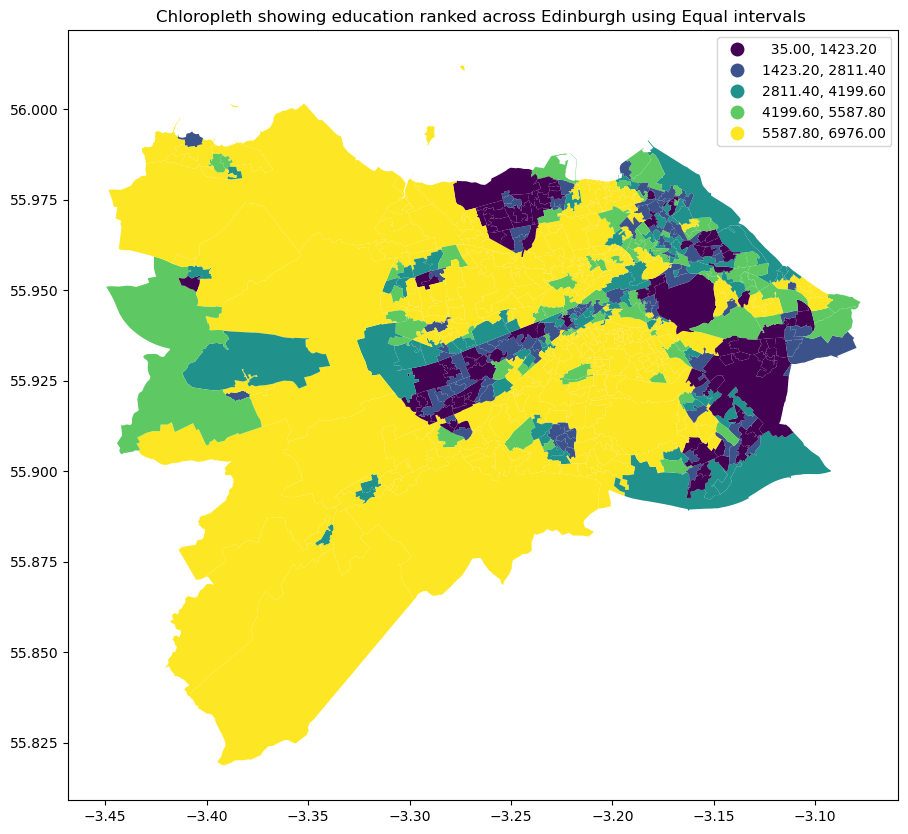

In [50]:
fig, ax = plt.subplots(figsize=(12, 10))
Edinburgh_Wards.plot(column='EduRank', ax=ax,
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins},
        )
plt.title("Chloropleth showing education ranked across Edinburgh using Equal intervals ")
plt.show()

#use Matplotlib to create a map of the data using intervals as created prior, (ei), therefore equal intervals.

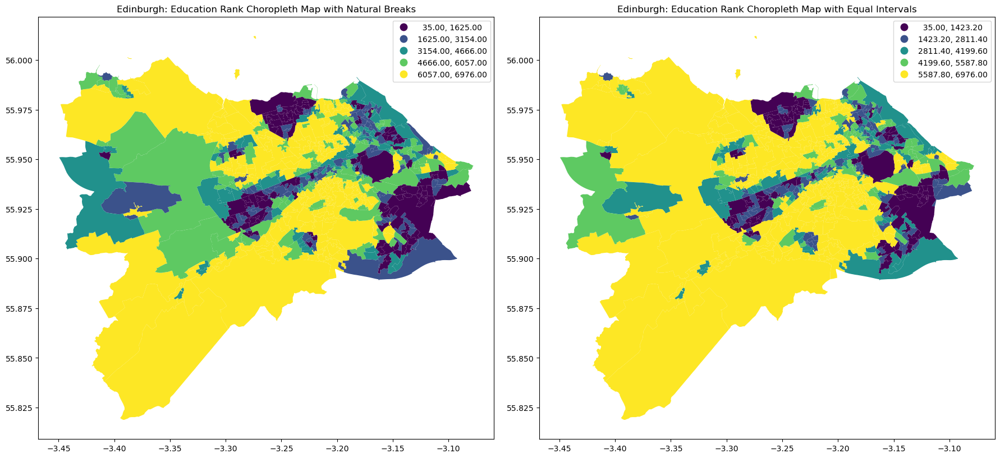

In [53]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8))

Edinburgh_Wards.plot(column='EduRank', ax=axs[0],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_nb.bins}
        )

axs[0].set_title("Edinburgh: Education Rank Choropleth Map with Natural Breaks")

Edinburgh_Wards.plot(column='EduRank', ax=axs[1],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins})

axs[1].set_title("Edinburgh: Education Rank Choropleth Map with Equal Intervals")

#Similarly to the dual histograms axis [1] and [2] utalised again, with similar code however this time instead of histogram its plotting 

plt.tight_layout() 
plt.show()

In [54]:
fig = px.choropleth_map(
    Edinburgh_Wards,
    geojson=Edinburgh_Wards.geometry,
    locations=Edinburgh_Wards.index,
    color="IncRankv2",
    color_continuous_scale="Viridis",
    hover_name="DZName",
    labels={"IncRankv2": "IncRankv2"},
    map_style="carto-positron",
    center={"lat": 55.95, "lon": -3.19},
    zoom=9,
    opacity=0.8,
)
fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0})
fig.show()

#Replotting Income Rank map again for easy visual comparison with the Education Rank map to show a possible visual correlation.
#Both cloropleths look similar visually, with areas such as the South East Craigmiller area showing both low levels of education and poor income.
#Displaying that income and education rates/ranks are likely correlated/related in some aspect. 

In [63]:
from shapely.geometry import Polygon
import requests
import pandas as pd
import geopandas as gpd

url_glasgow ="https://maps.gov.scot/server/rest/services/ScotGov/PeopleSociety/MapServer/7/query?where=LAName%3D%27Glasgow+City%27&text=&objectIds=&time=&timeRelation=esriTimeRelationOverlaps&geometry=&geometryType=esriGeometryEnvelope&inSR=&spatialRel=esriSpatialRelIntersects&distance=&units=esriSRUnit_Meter&relationParam=&outFields=*&returnGeometry=true&returnTrueCurves=false&maxAllowableOffset=&geometryPrecision=&outSR=&havingClause=&returnIdsOnly=false&returnCountOnly=false&orderByFields=&groupByFieldsForStatistics=&outStatistics=&returnZ=false&returnM=false&gdbVersion=&historicMoment=&returnDistinctValues=false&resultOffset=&resultRecordCount=&returnExtentOnly=false&sqlFormat=none&datumTransformation=&parameterValues=&rangeValues=&quantizationParameters=&featureEncoding=esriDefault&f=geojson"

response = requests.get(url_glasgow)
response

#utalised the given url for Glasgow SimD and code in order to compare desired outputs/statistics with Edinburgh

<Response [200]>

In [64]:
data = response.json()
data

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'id': 3351,
   'geometry': {'type': 'Polygon',
    'coordinates': [[[-4.325710653918472, 55.84701279108881],
      [-4.326153164212504, 55.8469325191929],
      [-4.327783867108311, 55.84668595430469],
      [-4.327899323235207, 55.84674668117934],
      [-4.328326942304913, 55.84668465851606],
      [-4.328881141884027, 55.8466022616186],
      [-4.328863037152116, 55.84656665434077],
      [-4.330065557608426, 55.84637310681865],
      [-4.330198961621295, 55.8461998149633],
      [-4.330715489661285, 55.84628888731298],
      [-4.330920075560882, 55.8459704443716],
      [-4.331356834233112, 55.84526113387144],
      [-4.3315673384221824, 55.84504144070613],
      [-4.3316655933325015, 55.84481488844978],
      [-4.3300398443221395, 55.84414167834789],
      [-4.3277789110869405, 55.84339660245825],
      [-4.326982079736873, 55.84316003475716],
      [-4.326476193875928, 55.84405038915921],
      [-4.326190192051532

In [65]:
gdf = gpd.GeoDataFrame.from_features(data["features"])
gdf.head()

,geometry,objectid,datazone,dzname,laname,sape2017,wape2017,rankv2,quintilev2,decilev2,...,crimerate,crimerank,housenumoc,housenumnc,houseocrat,housencrat,houserank,shape_leng,st_area(shape),st_length(shape)
0,"POLYGON ((-4.32571 55.84701, -4.32615 55.84693...",3351,S01009856,Mosspark - 05,Glasgow City,642,431,2692,2,4,...,172,3827.0,132,12,21%,2%,848.0,1366.395492,106802.776667,1366.395492
1,"POLYGON ((-4.27189 55.86998, -4.27257 55.87021...",3791,S01010296,Woodlands - 08,Glasgow City,703,559,1749,2,3,...,543,859.0,250,16,38%,2%,107.0,1066.977267,40436.400011,1066.977267
2,"POLYGON ((-4.26933 55.83811, -4.27288 55.83770...",3403,S01009908,Strathbungo - 04,Glasgow City,1037,804,4396,4,7,...,465,1153.0,176,56,17%,5%,855.0,1447.407105,90714.020243,1447.407105
3,"POLYGON ((-4.25912 55.82665, -4.25941 55.82648...",3506,S01010011,Mount Florida - 01,Glasgow City,728,518,1374,1,2,...,304,2199.0,124,36,17%,5%,938.0,1272.494457,59258.767062,1272.494457
4,"POLYGON ((-4.33427 55.89007, -4.33439 55.89027...",3903,S01010408,Kelvinside and Jordanhill - 01,Glasgow City,550,358,2841,3,5,...,219,3133.0,86,16,16%,3%,1407.0,2156.148438,168093.898062,2156.148438


In [66]:
gdf.crs is None

#As done prior, check crs for coordinates, if true they must be changed to epsg4326

True

In [71]:
gdf = gdf.set_crs('epsg:4326')

#Set crs to correct coordinate system so polygon lon/lat will be correct

In [78]:
gdf.explore(column='quintilev2', tooltip=False)

#Tooltip = False removes a crowded pop up when exploring the map

In [86]:
fig = px.choropleth_map(gdf,
                           geojson=gdf.geometry,
                           locations=gdf.index,
                           color="quintilev2",
                           color_continuous_scale="ylgn",
                           range_color=(1, 5),
                           opacity=0.8,
                           center={"lat": 55.85, "lon": -4.2},
                           map_style="carto-positron",
                           zoom=10)
                        
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

#Using Plotly display a cloropleth map of Glasgow displaying Quintile 

In [80]:
fig = px.choropleth_map(Edinburgh_Wards,
                                        geojson=Edinburgh_Wards.geometry,
                                        locations=Edinburgh_Wards.index,
                                        color="Quintilev2",
                                        color_continuous_scale="ylgn",
                                        range_color=(1, 5),
                                        opacity=0.8,
                                        hover_name="DZName",
                                        center={"lat": 55.95, "lon": -3.19},
                                        map_style="carto-positron",
                                        zoom=9.5,)

fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0})
fig.show()

#Using Plotly display a cloropleth map of Edinburgh displaying Quintile 

In [81]:
fig = px.choropleth_map(gdf,
                           geojson=gdf.geometry,
                           locations=gdf.index,
                           color="quintilev2",
                           color_continuous_scale="ylgn",
                           range_color=(1, 5),
                           opacity=0.8,
                           center={"lat": 55.866193, "lon": -4.258246},
                           map_style="carto-positron",
                           zoom=9.5)
                        
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

fig = px.choropleth_map(Edinburgh_Wards,
                                        geojson=Edinburgh_Wards.geometry,
                                        locations=Edinburgh_Wards.index,
                                        color="Quintilev2",
                                        color_continuous_scale="ylgn",
                                        range_color=(1, 5),
                                        opacity=0.8,
                                        hover_name="DZName",
                                        center={"lat": 55.95, "lon": -3.19},
                                        map_style="carto-positron",
                                        zoom=9.5,)

fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0})
fig.show()

#Put both code together to compare maps visually easier, enabling us to see generally Edinburgh has more areas in a higher quintile.
#Insinuating visually, Glasgow has far more deprived areas than Edinburgh

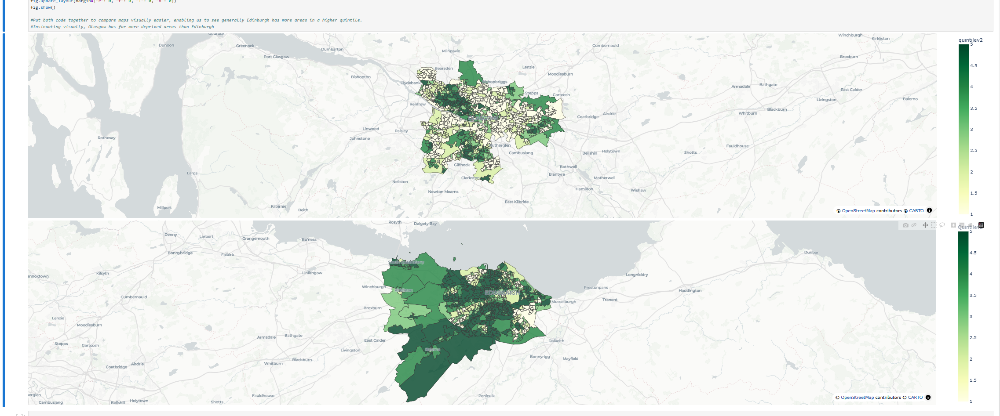